## This script calculate the topic similarity between international and non-international collaborated papers at country-discipline level with **sample** the fixed number of publications from each country-discipline pair to **control the influence of size**


In [32]:
import pandas as pd
import numpy as np
import itertools
from multiprocessing import Pool
from tqdm import tqdm
from scipy.spatial import distance
import random
import math
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity
from multiprocessing import Pool, cpu_count
import multiprocessing as mp
from scipy import stats

In [2]:
embedding_path = "/gpfs/slate-sciencegenome/Embeddings/Data/wos_embedding_specter_all.npz"

In [3]:
embedding_file = np.load(embedding_path)
embedding = embedding_file['emb']
uids = embedding_file['uids']

In [4]:
pub_all_path = "../../data/dropbox/LaborDivision/data/deriveddata/all/pub_author.csv"
pub_all = pd.read_csv(pub_all_path)
pub_all = pub_all.drop(columns=['seqno','lastname','num_author'])

In [5]:
uid_path = "../../data/dropbox/LaborDivision/data/cleanedraw/ostbk_uid.pkl"
uid_df = pd.read_pickle(uid_path)

In [6]:
pub_all['ost_bk'] = pub_all['ost_bk'].astype('str')
pub_all['uid'] = pub_all['ost_bk'].map(uid_df)

In [7]:
len(uids)

84162157

In [8]:
len(embedding)

84162157

In [9]:
path = "../../data/dropbox/LaborDivision/data/additionaldata/list_discipline.txt"
dis_df = pd.read_csv(path,sep="|", on_bad_lines='skip')
dis_map = dict(zip(dis_df['Code_Discipline'],dis_df['EDiscipline']))

In [10]:
dis_df.head()

,Code_Discipline,EGrande_Discipline,EDiscipline,ESpecialite
0,1,Natural Sciences and Engineering,Biology,Agricult & Food Science
1,2,Natural Sciences and Engineering,Biology,Botany
2,3,Natural Sciences and Engineering,Biology,Dairy & Animal Science
3,4,Natural Sciences and Engineering,Biology,Ecology
4,5,Natural Sciences and Engineering,Biology,Entomology


### create an dict which records uid and the index in uids array to retrieve the embedding from the embedding array

In [11]:
uid_index_dict={}
for index, uid in tqdm(enumerate(uids)):
    uid_index_dict[uid]=index

84162157it [01:37, 859196.74it/s]


In [12]:
uid_index_dict['WOS:000474332900003']

76090832

### create a dict to record publications at country-discipline level with distinguish whether international or national

In [13]:
cntry_dis_pubs = pub_all[['cntry','dis','intl','uid']].drop_duplicates()

In [14]:
cntry_dis_pubs = cntry_dis_pubs.replace(to_replace={'dis':dis_map})

In [15]:
cntry_dis_dict = {}
cntry_dis_pubs_array = cntry_dis_pubs[['cntry','dis','intl','uid']].values
# Iterate through the dataframe rows
for row in tqdm(cntry_dis_pubs_array):
    cntry = row[0]
    dis = row[1]
    intl = row[2]
    uid = row[3]
    
    # Check if the key_A already exists in the nested dictionary
    if (cntry,dis) in cntry_dis_dict:
        # Check if the key_B already exists for the key_A
        if intl in cntry_dis_dict[(cntry,dis)]:
            # Append the value_C to the existing list
            cntry_dis_dict[(cntry,dis)][intl].append(uid)
        else:
            # Create a new key_B entry with a list containing value_C
            cntry_dis_dict[(cntry,dis)][intl] = [uid]
    else:
        # Create a new key_A entry with a nested dictionary containing key_B and value_C
        cntry_dis_dict[(cntry,dis)] = {intl: [uid]}

100%|███████████████████████████| 21863524/21863524 [00:29<00:00, 751617.02it/s]


In [16]:
def return_embeddings(pubs,uid_index_dict,embedding):
    embed_index = [uid_index_dict[pub] for pub in pubs if pub in uid_index_dict]
    if embed_index:
        embed_vectors = embedding[embed_index]
        return embed_vectors
    return None

In [17]:
def sample_embeddings(cntry_dis_emb_raw, minimum_size=20, sample_size=100):
    embeddings_sample = {}
    for cntry_dis, intl_embeds in cntry_dis_emb_raw.items():
        embeddings_sample[cntry_dis]={}
        for intl, embeds in intl_embeds.items():
            if embeds is not None and embeds.shape[0]> minimum_size:
                resampled_indices = np.random.choice(len(embeds), size=sample_size, replace=True)
                embeddings_sample[cntry_dis][intl] = embeds[resampled_indices]
    return embeddings_sample

In [18]:
def precompute_raw_embeddings(cntry_dist_dict, uid_index_dict, embedding):
    embeddings_raw = {}
    for cntry_dis, intl_uids in cntry_dis_dict.items():
        embeddings_raw[cntry_dis]={}
        for intl in intl_uids.keys():
            emb = return_embeddings(intl_uids[intl], uid_index_dict, embedding)
            embeddings_raw[cntry_dis][intl]=emb
    return embeddings_raw

In [19]:
def cal_similarity(cntry_dis_embedding):
    results = []
    for cntry_dis, intl_pubs in cntry_dis_embedding.items():
        pubs1 = intl_pubs.get(1)
        pubs2 = intl_pubs.get(0)
        if pubs1 is not None and pubs2 is not None:
            similarity = 1-distance.cosine(np.mean(pubs1, axis=0), np.mean(pubs2, axis=0))
            results.append([cntry_dis[0], cntry_dis[1], similarity])
            
    results = pd.DataFrame(results, columns = ['cntry','dis','similarity'])
    results = results.groupby(['cntry'])['similarity'].mean().reset_index()
    return results

In [20]:
cntry_dis_embed_raw = precompute_raw_embeddings(cntry_dis_dict, uid_index_dict, embedding)
cntry_similarity_raw = cal_similarity(cntry_dis_embed_raw)

In [21]:
iteration_num = 100
cntry_similarity_sampled = pd.DataFrame()
for _ in tqdm(range(iteration_num)):
    embeds_sampled = sample_embeddings(cntry_dis_embed_raw)
    sampled_res = cal_similarity(embeds_sampled)
    cntry_similarity_sampled = pd.concat([cntry_similarity_sampled, sampled_res])

100%|█████████████████████████████████████████| 100/100 [00:26<00:00,  3.73it/s]


### read st and color scheme

In [22]:
stgroup_path = '../../data/dropbox/LaborDivision/data/additionaldata/cntry_classification/cntry_st.csv'
stgroup_df=pd.read_csv(stgroup_path)[['Code','class']].drop_duplicates()
stgroup_df=stgroup_df.replace(to_replace={'class':{'Others':'Lagging'}})
stgroup_df.head()

,Code,class
0,AFG,Lagging
1,ALB,Lagging
2,DZA,Lagging
3,AND,Lagging
4,AGO,Lagging


In [23]:
color_scheme_path = '../../data/dropbox/LaborDivision/data/additionaldata/cntry_classification/color_scheme.csv'
color_scheme = pd.read_csv(color_scheme_path)
color_scheme = color_scheme[color_scheme['type']=='st']
color_dict = dict(zip(color_scheme['class'], color_scheme['color']))

In [24]:
def merge_with_group(df, group_df):
    df = df.merge(group_df, left_on='cntry', right_on='Code')
    df = df.groupby(['cntry','class'])['similarity'].mean().reset_index()
    return df

### aggregate data to country level

In [25]:
def plot(df, color_dict):    
    fig, ax=plt.subplots()
    sns.boxplot(x='class',y='similarity',data=df,
                boxprops={'facecolor':'none', 'edgecolor':'#404040'},
                medianprops={'color':'#737373'},
                whiskerprops={'color':'#737373'},
                capprops={'color':'#737373'},
                order=color_dict.keys(),
                fliersize=0,
                ax=ax)
    sns.stripplot(x='class',y='similarity',data=df,ax=ax, order=color_dict.keys(), color='#6EBF34', alpha=0.7)
    ax.set_ylabel("Publication similarity", fontsize=12)
    ax.set_xlabel("")
    ax.tick_params(axis='both', which='major', labelsize=12)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    return fig, ax
#plt.savefig("../../data/dropbox/LaborDivision/figs/pub_similarity_derived_cntry_dis.pdf",bbox_inches='tight')

In [28]:
group_similarity_raw

,cntry,class,similarity
0,ABW,Lagging,0.940340
1,AFG,Lagging,0.918398
2,AGO,Lagging,0.873823
3,ALB,Lagging,0.910901
4,AND,Lagging,0.746110
...,...,...,...
192,XKX,Lagging,0.898209
193,YEM,Lagging,0.895442
194,ZAF,Proficient,0.986140
195,ZMB,Lagging,0.947956


In [67]:
def p_value_to_label(p_value):
    if p_value < 0.001:
        return "***"
    elif p_value < 0.01:
        return "**"
    elif p_value < 0.05:
        return "*"
    elif p_value < 0.1:
        return "+"
    else:
        return "ns"  # not significant

def annotate_significance(ax, df, groups, yshift, hshift, labelshift):
    for x1,grp1 in enumerate(groups[:-1]):
        x2 = x1+1
        grp2 = groups[x2]
        
        grp1_value = df[df['class']==grp1]['similarity']
        grp2_value = df[df['class']==grp2]['similarity']
        
        t_stat, p_value = stats.ttest_ind(grp1_value, grp2_value, alternative='greater', equal_var=False)
        significance_label = p_value_to_label(p_value)
        
        y = df['similarity'].max()+yshift+(x1*yshift)
        ax.plot([x1, x1, x2, x2], [y, y+hshift, y+hshift, y], lw=1.5, c='k')
        ax.text((x1+x2)*.5, y+labelshift, significance_label, ha='center', va='bottom', color='k')
        
    return ax

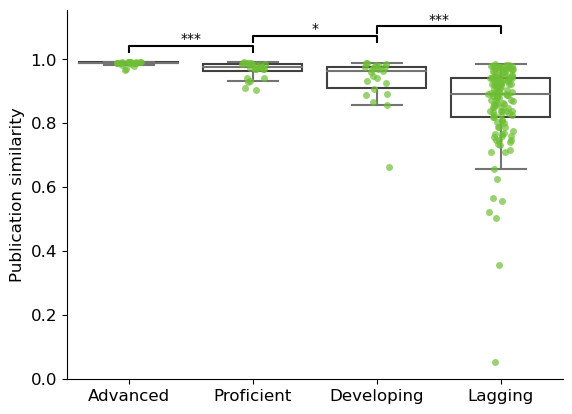

In [71]:
group_similarity_raw = merge_with_group(cntry_similarity_raw, stgroup_df)
fig, ax = plot(group_similarity_raw, color_dict)
ax = annotate_significance(ax, group_similarity_raw, list(color_dict.keys()), 0.03, 0.02, 0.02)
plt.savefig("../../data/dropbox/LaborDivision/figs/pub_similarity_derived_cntry_dis.pdf",bbox_inches='tight')

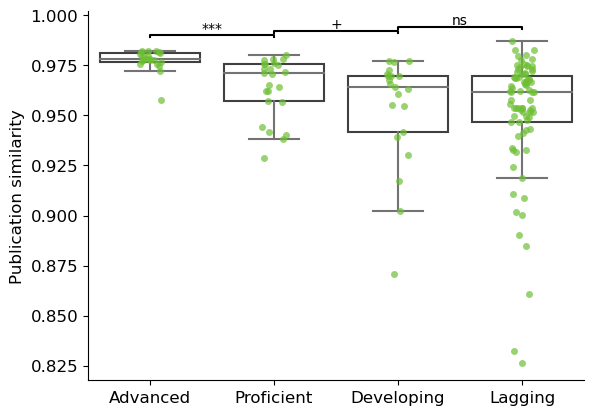

In [70]:
group_similarity_sampled = merge_with_group(cntry_similarity_sampled, stgroup_df)
fig, ax = plot(group_similarity_sampled, color_dict)
ax = annotate_significance(ax, group_similarity_sampled, list(color_dict.keys()),0.002,0.001,0.001)
plt.savefig("../../data/dropbox/LaborDivision/figs/pub_similarity_derived_cntry_dis_sampled.pdf",bbox_inches='tight')